# Safe v2: portfolio-level risk controls (research)

**Why a v2.** In the paper-trading forward test (from April 2026) Safe held about 80% equities in July–August, split between small caps (IWM) and Nasdaq (QQQ), and fell more than the S&P 500. The cause is structural: when bonds and gold fail the trend filter, momentum weighting with the 40% "turbo" cap concentrates the portfolio in two equity ETFs, and v1 has no limit on total risk.

**What changes** (selection rules unchanged):
1. The 40% turbo cap applies only when at least 3 risky assets are selected.
2. Total equity weight is capped at 60%.
3. Ex-ante volatility of the portfolio is capped at 10%: portfolio volatility = sqrt(w' Σ w × 252), with Σ the covariance matrix of the last 63 daily returns (about 3 months); if it exceeds 10%, all risky weights are scaled by 10% / volatility and the rest goes to T-bills.

**Variant v2b** (no volatility model, only weight limits): only the strongest asset can reach 40%, all others stay at 25%, and total equity is capped at 60%.

**Parameters fixed before looking at the results**: 10% is roughly the long-run volatility of v1, 60% the equity share of a 60/40. They are not optimised. The sensitivity grid at the end uses only data before April 2026.

**Out-of-sample**: holding months from April 2026 onwards, the same period as the v1 forward test. v1 stays live and keeps its track record; v2 would start a new one.

In [1]:
import os
import sys

import numpy as np
import pandas as pd

sys.path.append(os.path.join("..", "src"))
from data import download_prices, prepare_monthly
from strategies import trend_momentum_signal, correlation_filter, momentum_weights, safe_v2_weights, safe_v2b_weights, safe_v3_weights, SAFE_EQUITY
from backtest import run_backtest, allocation_stats, stress_test, daily_path, max_drawdown, perf_summary
import benchmarks as bm

np.random.seed(42)
DATA_DIR = os.path.join("..", "data")

/opt/miniconda3/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
UNIVERSE = ["SPY", "QQQ", "IWM", "VWO", "GLD", "SHV", "IEF", "TLT", "TIP", "LQD"]
TICKER_COSTS = {"SPY": 0.0002, "QQQ": 0.0003, "SHV": 0.0001, "IEF": 0.0002, "TLT": 0.0003,
                "IWM": 0.0004, "GLD": 0.0004, "LQD": 0.0004, "VWO": 0.0008, "TIP": 0.0003}
OOS_START = pd.Timestamp("2026-04-30")      # first holding month of the forward test (April 2026)

prices = download_prices(UNIVERSE, years=20, cache_path=os.path.join(DATA_DIR, "prices_safe.csv"))
md = prepare_monthly(prices, sma_window=200)

w_v1 = momentum_weights(correlation_filter(trend_momentum_signal(md), md.mom_3m, md.daily_returns, 5, 0.80),
                        md.mom_3m, 0.25, 0.40, 0.05)
w_v2 = safe_v2_weights(md)       # v2:  turbo only with 3+ assets, equity <= 60%, vol target 10%
w_v2b = safe_v2b_weights(md)     # v2b: only the best asset can reach 40%, equity <= 60%, no vol target
for W in (w_v1, w_v2, w_v2b): bm.check_weights(W)

Downloaded 2006-10-19 -> 2026-10-14. First valid date per ETF:
  SPY   2006-10-19
  QQQ   2006-10-19
  IWM   2006-10-19
  VWO   2006-10-19
  GLD   2006-10-19
  SHV   2007-01-11
  IEF   2006-10-19
  TLT   2006-10-19
  TIP   2006-10-19
  LQD   2006-10-19
Weights check: every month sums to 100%.

Weights check: every month sums to 100%.

Weights check: every month sums to 100%.



## 1. What changes in the portfolio
Equity share and model weights by holding month (a weight decided at the end of March is held in April).

In [3]:
def by_holding_month(W):
    H = W.copy(); H.index = H.index + pd.offsets.MonthEnd(1); return H

exposure = pd.DataFrame({
    "v1 equity %": by_holding_month(w_v1)[SAFE_EQUITY].sum(axis=1) * 100,
    "v2 equity %": by_holding_month(w_v2)[SAFE_EQUITY].sum(axis=1) * 100,
    "v2b equity %": by_holding_month(w_v2b)[SAFE_EQUITY].sum(axis=1) * 100,
    "v1 T-bills %": by_holding_month(w_v1)["SHV"] * 100,
    "v2 T-bills %": by_holding_month(w_v2)["SHV"] * 100,
    "v2b T-bills %": by_holding_month(w_v2b)["SHV"] * 100,
}).round(1)
print("Last 9 holding months:")
print(exposure.tail(9).to_string(), "\n")
for v in ["v1", "v2", "v2b"]:
    e = exposure[f"{v} equity %"]
    print(f"{v:<4} average equity {e.mean():.0f}% | months with equity > 60%: {(e > 60.01).sum()}")

print("\nModel weights in the forward-test period (%):")
for name, W in [("v1", w_v1), ("v2", w_v2), ("v2b", w_v2b)]:
    H = by_holding_month(W).loc[OOS_START:]
    print(f"\n{name}"); print((H.loc[:, (H > 0).any()] * 100).round(1).to_string())

Last 9 holding months:
            v1 equity %  v2 equity %  v2b equity %  v1 T-bills %  v2 T-bills %  v2b T-bills %
Date                                                                                         
2026-02-28         52.0         33.0          52.0           8.0          41.6            8.0
2026-03-31         44.1         25.4          43.1           6.9          46.3            7.3
2026-04-30         31.1         15.6          31.1          16.2          58.1           16.2
2026-05-31         91.3         50.1          60.0           4.0          46.0           32.9
2026-06-30         91.4         51.2          60.0           8.6          48.8           40.0
2026-07-31         80.0         47.1          60.0           6.4          42.2           16.4
2026-08-31         80.0         48.9          60.0          20.0          51.1           40.0
2026-09-30         25.0         25.0          25.0          75.0          75.0           75.0
2026-10-31         25.0         25.0 

## 2. Full-sample backtest (net of costs)

PERFORMANCE: Safe v1  (2006-10 -> 2026-09, Sharpe uses rf = 2%)
                       CAGR Volatility Sharpe  Max DD
Gross (no costs)      8.96%      9.35%   0.74  -14.2%
Net (per-ETF costs)   8.66%      9.34%   0.71  -14.3%
Benchmark (SPY)      10.94%     15.31%   0.58  -50.8% 



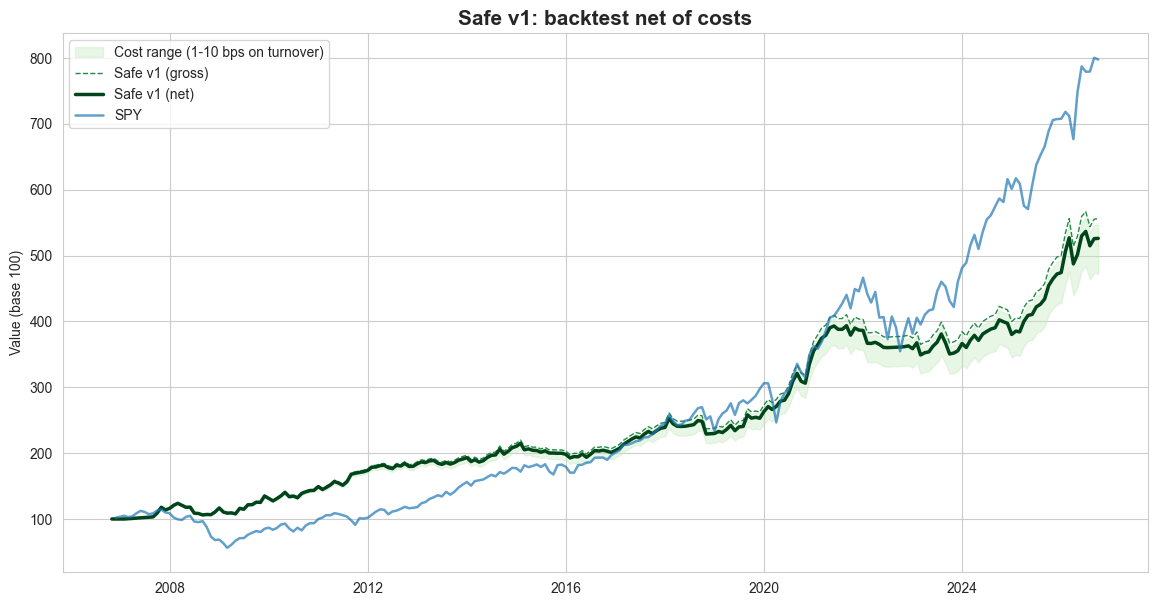

PERFORMANCE: Safe v2  (2006-10 -> 2026-09, Sharpe uses rf = 2%)
                       CAGR Volatility Sharpe  Max DD
Gross (no costs)      7.48%      7.25%   0.76  -10.4%
Net (per-ETF costs)   7.23%      7.25%   0.72  -10.5%
Benchmark (SPY)      10.94%     15.31%   0.58  -50.8% 



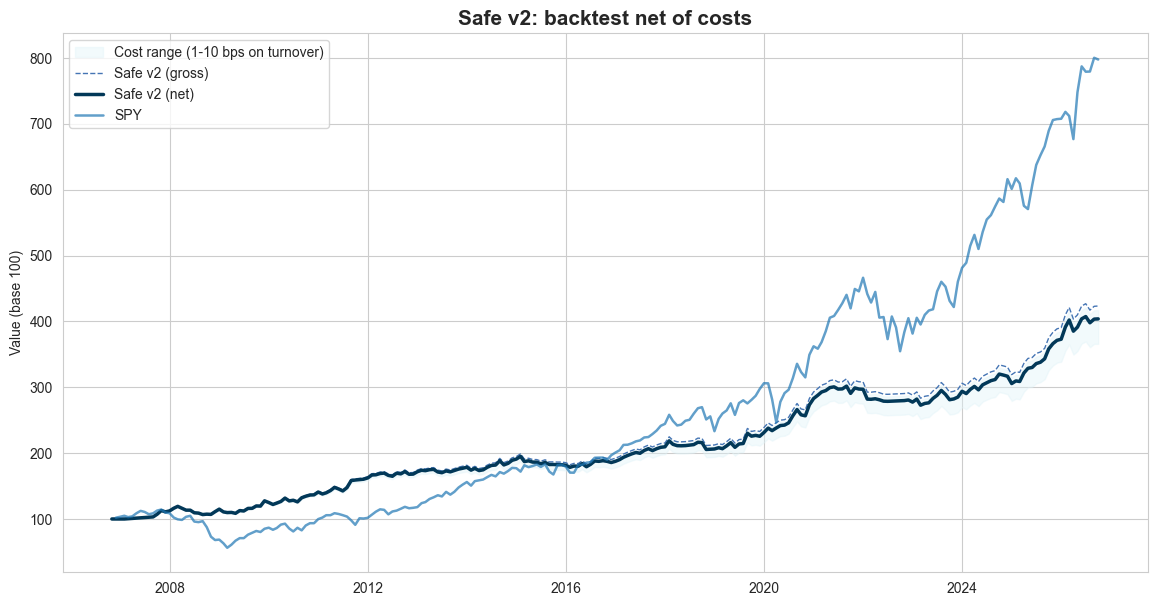

PERFORMANCE: Safe v2b  (2006-10 -> 2026-09, Sharpe uses rf = 2%)
                       CAGR Volatility Sharpe  Max DD
Gross (no costs)      8.33%      8.43%   0.75  -11.9%
Net (per-ETF costs)   8.06%      8.42%   0.72  -12.0%
Benchmark (SPY)      10.94%     15.31%   0.58  -50.8% 



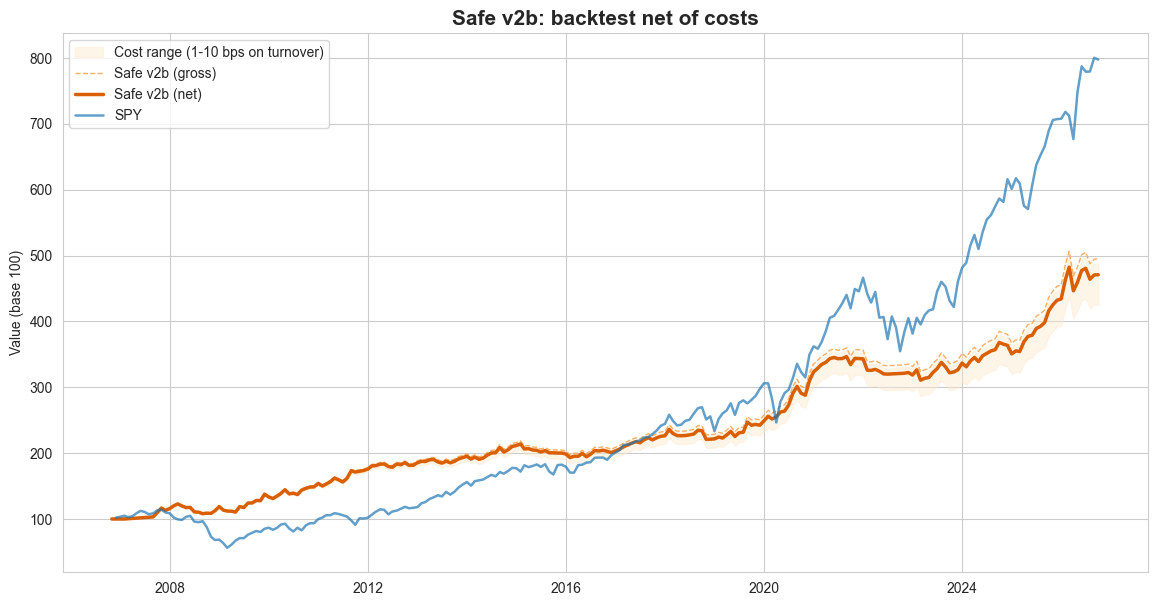

In [4]:
bt_v1 = run_backtest(w_v1, md.returns, TICKER_COSTS, "Safe v1")
bt_v2 = run_backtest(w_v2, md.returns, TICKER_COSTS, "Safe v2", colors=("#4575b4", "#023858", "#e0f3f8"))
bt_v2b = run_backtest(w_v2b, md.returns, TICKER_COSTS, "Safe v2b", colors=("#fdae61", "#d95f02", "#fee8c8"))

## 3. In-sample vs out-of-sample (forward-test period)
Monthly returns hide intra-month drawdowns, so the out-of-sample section also uses an approximate daily path (month-end weights held through the following month).

IN-SAMPLE (to Mar 2026, monthly returns, annualised)
            CAGR Volatility Sharpe  Max DD
Safe v1    8.46%      9.31%   0.69  -14.3%
Safe v2    7.16%      7.28%   0.71  -10.5%
Safe v2b   7.98%      8.43%   0.71  -12.0%
S&P 500   10.30%     15.30%   0.54  -50.8% 

Monthly returns in the forward-test period (%, USD, backtest):
          Safe v1  Safe v2  Safe v2b    SPY
Date                                       
Apr 2026     2.89     1.59      2.89  10.51
May 2026     5.66     3.23      3.92   5.26
Jun 2026     1.29     0.84      0.68  -1.03
Jul 2026    -4.06    -2.31     -3.46   0.03
Aug 2026     2.10     1.39      1.40   2.68
Sep 2026     0.08     0.09      0.08  -0.33 

OUT-OF-SAMPLE, daily path 2026-04-01 -> 2026-10-13 (USD, no costs, cumulative return):
          Return %  Vol (ann.) %  Max DD (daily) %  Beta to SPY
Safe v1       8.68         14.19             -6.00         1.00
Safe v2       5.62          8.05             -3.44         0.58
Safe v2b      6.25         10.71  

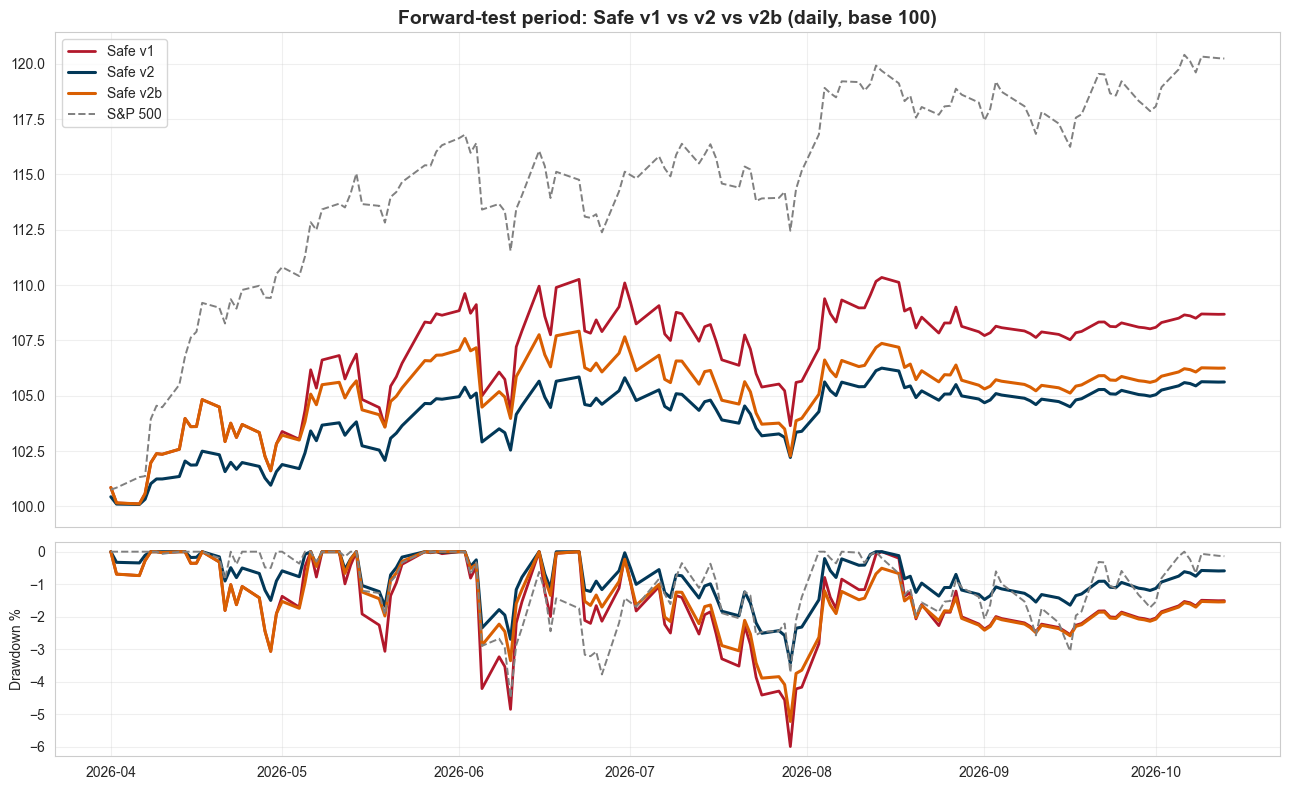

In [5]:
# In-sample: annualised (19 years). Out-of-sample: cumulative, NOT annualised (only ~6 months).
spy = md.returns["SPY"].loc[bt_v1["net"].index]
series = {"Safe v1": bt_v1["net"], "Safe v2": bt_v2["net"], "Safe v2b": bt_v2b["net"], "S&P 500": spy}
ins = pd.DataFrame({k: perf_summary(v[v.index < OOS_START]) for k, v in series.items()}).T
print("IN-SAMPLE (to Mar 2026, monthly returns, annualised)"); print(ins.to_string(), "\n")

monthly = pd.DataFrame({"Safe v1": bt_v1["net"], "Safe v2": bt_v2["net"], "Safe v2b": bt_v2b["net"], "SPY": md.returns["SPY"]}).loc[OOS_START:]
monthly.index = monthly.index.strftime("%b %Y")
print("Monthly returns in the forward-test period (%, USD, backtest):")
print((monthly * 100).round(2).to_string(), "\n")

d_v1 = daily_path(w_v1, md.daily_returns).loc["2026-04-01":]
d_v2 = daily_path(w_v2, md.daily_returns).loc["2026-04-01":]
d_v2b = daily_path(w_v2b, md.daily_returns).loc["2026-04-01":]
d_spy = md.daily_returns["SPY"].loc[d_v1.index]
oos = pd.DataFrame({
    "Return %": [((1 + x).prod() - 1) * 100 for x in (d_v1, d_v2, d_v2b, d_spy)],
    "Vol (ann.) %": [x.std() * np.sqrt(252) * 100 for x in (d_v1, d_v2, d_v2b, d_spy)],
    "Max DD (daily) %": [max_drawdown(x) * 100 for x in (d_v1, d_v2, d_v2b, d_spy)],
    "Beta to SPY": [x.cov(d_spy) / d_spy.var() for x in (d_v1, d_v2, d_v2b, d_spy)],
}, index=["Safe v1", "Safe v2", "Safe v2b", "SPY"]).round(2)
print(f"OUT-OF-SAMPLE, daily path {d_v1.index[0].date()} -> {d_v1.index[-1].date()} (USD, no costs, cumulative return):")
print(oos.to_string())

import matplotlib.pyplot as plt
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [3, 1.3]}, sharex=True)
for x, lab, st in [(d_v1, "Safe v1", dict(color="#b2182b", lw=2)), (d_v2, "Safe v2", dict(color="#023858", lw=2.2)),
                   (d_v2b, "Safe v2b", dict(color="#d95f02", lw=2.2)),
                   (d_spy, "S&P 500", dict(color="grey", lw=1.4, ls="--"))]:
    eq = (1 + x).cumprod() * 100
    a1.plot(eq, label=lab, **st)
    a2.plot((eq / eq.cummax() - 1) * 100, **st)
a1.set_title("Forward-test period: Safe v1 vs v2 vs v2b (daily, base 100)", fontsize=14, fontweight="bold")
a1.legend(loc="upper left"); a1.grid(alpha=0.3); a2.set_ylabel("Drawdown %"); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Backtest vs paper account.** The backtest uses US-listed ETFs in USD and month-end execution; the paper account holds EUR-listed UCITS ETFs and trades a few days into the month. Differences of a few percentage points from the factsheet are expected (EUR/USD, timing, tracking). The comparison that matters is v1 vs v2 on identical data.

## 4. Does v2 still add value against the benchmarks?

In [6]:
R = md.returns
RISKY = [c for c in md.prices.columns if c != "SHV"]
ff = bm.load_fama_french(os.path.join(DATA_DIR, "ff_factors_monthly.csv"))
rf = ff["RF"] if ff is not None else R["SHV"].fillna(0.0)
benchmarks = {
    "Safe v1 (net)":       bt_v1["net"],
    "60/40 (SPY/IEF)":     bm.returns_from_weights(bm.fixed_mix(md.prices.index, {"SPY": 0.6, "IEF": 0.4}), R),
    "ERC universe":        bm.returns_from_weights(bm.erc(md.daily_returns, md.prices.index, RISKY), R),
    "Trend 1/N (10m SMA)": bm.returns_from_weights(bm.naive_trend(md.prices, RISKY), R),
}
for name, bt, W in [("Safe v2 (net)", bt_v2, w_v2), ("Safe v2b (net)", bt_v2b, w_v2b)]:
    S, B, RF = bm.align_sample(bt["net"], benchmarks, rf, W)
    bm.benchmark_comparison(S, B, RF, name)

Fama-French: 1963-07 -> 2026-08, downloaded
Common sample: 2007-09 -> 2026-08 (228 months)

BENCHMARK COMPARISON: Safe v2 (net)
                      CAGR    Vol Sharpe    MaxDD Calmar  Active     TE     IR  Beta  Alpha  t(α) p(ΔSR)
Safe v2 (net)        7.45%  7.43%   0.82  -10.48%   0.71                                                
Safe v1 (net)        8.95%  9.57%   0.80  -14.29%   0.63  -1.58%  2.93%  -0.54  0.75  0.31%  0.98   0.73
60/40 (SPY/IEF)      8.20%  9.56%   0.73  -29.46%   0.28  -0.89%  9.29%  -0.10  0.33  3.78%  2.50   0.72
ERC universe         6.12%  7.37%   0.66  -19.79%   0.31   1.25%  6.83%   0.18  0.58  3.29%  2.48   0.45
Trend 1/N (10m SMA)  6.14%  5.59%   0.85   -8.16%   0.75   1.34%  4.35%   0.31  1.08  0.96%  1.07   0.84
Active = strategy - benchmark (ann.) | TE = tracking error | IR = Active / TE | Alpha, Beta from regressing strategy excess returns on benchmark excess returns (Newey-West t)
p(ΔSR) = p-value of the Sharpe difference (Jobson-Korkie / Memmel).

## 5. Sensitivity (in-sample only, data before April 2026)
A robust rule should not depend on the exact parameter. This grid is a check, not a way to pick the best cell.

In [7]:
grid = []
for tv in [0.08, 0.10, 0.12]:
    for me in [0.50, 0.60, 0.70]:
        w = safe_v2_weights(md, target_vol=tv, max_equity=me)
        first = w[w.sum(axis=1) > 0].index[0]
        gross = (w.shift(1) * md.returns).sum(axis=1).loc[first:]
        turn = w.diff().abs(); turn.loc[first] = w.loc[first]
        net = gross - (turn * pd.Series(TICKER_COSTS)).sum(axis=1).shift(1).fillna(0).loc[first:]
        net = net[net.index < OOS_START]
        s = perf_summary(net)
        grid.append({"Target vol": f"{tv:.0%}", "Max equity": f"{me:.0%}", **s})
print(pd.DataFrame(grid).to_string(index=False))

Target vol Max equity  CAGR Volatility Sharpe Max DD
        8%        50% 6.67%      6.49%   0.72  -9.1%
        8%        60% 6.71%      6.61%   0.71  -9.1%
        8%        70% 6.84%      6.70%   0.72  -9.1%
       10%        50% 6.99%      7.10%   0.70 -10.5%
       10%        60% 7.16%      7.28%   0.71 -10.5%
       10%        70% 7.28%      7.41%   0.71 -10.5%
       12%        50% 7.11%      7.54%   0.68 -11.2%
       12%        60% 7.38%      7.79%   0.69 -11.2%
       12%        70% 7.57%      7.96%   0.70 -11.2%


## 6. Another idea: size by risk instead of momentum (v3)

v1, v2 and v2b all have a Sharpe ratio of about 0.8: caps and volatility targets move the strategy along the same risk/return line (less risk, less return) but do not improve it. To improve the ratio, the weighting itself has to change. v3 keeps the same selection but weights the selected assets by inverse 60-day volatility (25% cap) instead of by momentum, plus the 60% equity cap. Bonds and gold then get a larger share relative to small caps and Nasdaq.

Weights check: every month sums to 100%.

PERFORMANCE: Safe v3 (inverse-vol)  (2006-10 -> 2026-09, Sharpe uses rf = 2%)
                       CAGR Volatility Sharpe  Max DD
Gross (no costs)      7.01%      6.47%   0.77   -9.8%
Net (per-ETF costs)   6.79%      6.47%   0.74   -9.9%
Benchmark (SPY)      10.94%     15.31%   0.58  -50.8% 



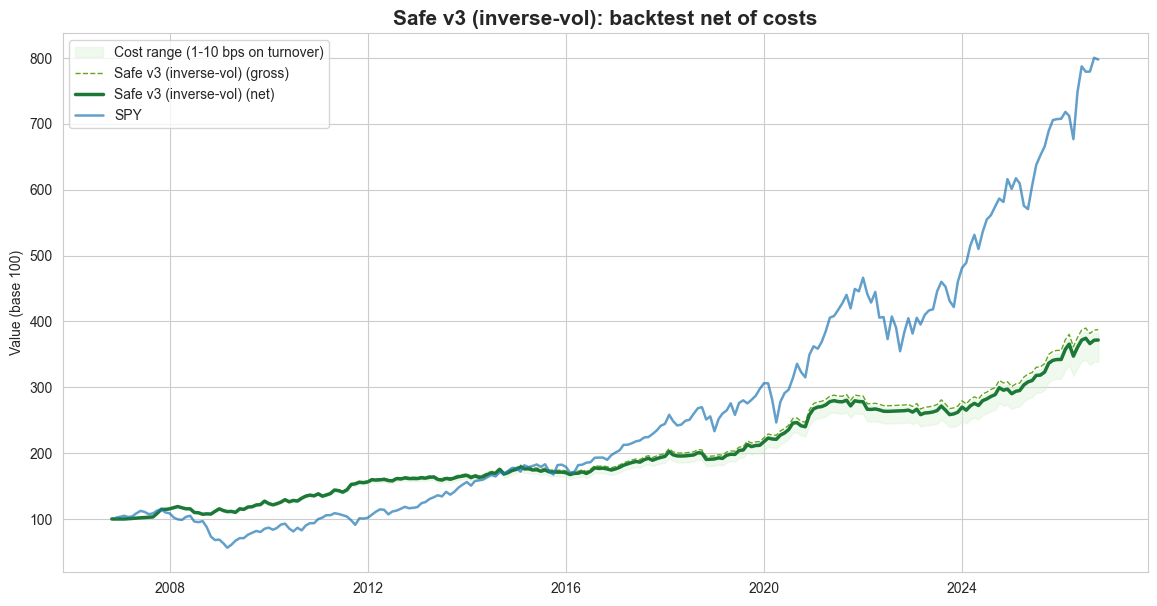

Full sample, net of costs (Sharpe = (CAGR - 2%) / vol):
           CAGR Volatility Sharpe  Max DD
Safe v1   8.66%      9.34%   0.71  -14.3%
Safe v2   7.23%      7.25%   0.72  -10.5%
Safe v2b  8.06%      8.42%   0.72  -12.0%
Safe v3   6.79%      6.47%   0.74   -9.9% 

Forward-test period, daily path (cumulative):
          Return %  Vol %  Max DD %  Beta
                                         
Safe v1       8.68  14.19     -6.00  1.00
Safe v2       5.62   8.05     -3.44  0.58
Safe v2b      6.25  10.71     -5.23  0.76
Safe v3       7.83   8.93     -3.26  0.65
SPY          20.24  12.20     -4.49  1.00
Common sample: 2007-09 -> 2026-08 (228 months)

BENCHMARK COMPARISON: Safe v3 (net)
                      CAGR    Vol Sharpe    MaxDD Calmar  Active     TE     IR  Beta  Alpha  t(α) p(ΔSR)
Safe v3 (net)        6.98%  6.63%   0.84   -9.88%   0.71                                                
Safe v1 (net)        8.95%  9.57%   0.80  -14.29%   0.63  -2.08%  3.90%  -0.53  0.66  0.56%  1.26 

In [8]:
w_v3 = safe_v3_weights(md)
bm.check_weights(w_v3)
bt_v3 = run_backtest(w_v3, md.returns, TICKER_COSTS, "Safe v3 (inverse-vol)", colors=("#66a61e", "#1b7837", "#d9f0d3"))

cmp = {}
for name, bt in [("Safe v1", bt_v1), ("Safe v2", bt_v2), ("Safe v2b", bt_v2b), ("Safe v3", bt_v3)]:
    cmp[name] = perf_summary(bt["net"])
print("Full sample, net of costs (Sharpe = (CAGR - 2%) / vol):")
print(pd.DataFrame(cmp).T.to_string(), "\n")

d_v3 = daily_path(w_v3, md.daily_returns).loc["2026-04-01":]
rows = []
for name, x in [("Safe v1", d_v1), ("Safe v2", d_v2), ("Safe v2b", d_v2b), ("Safe v3", d_v3), ("SPY", d_spy)]:
    rows.append({"": name, "Return %": ((1 + x).prod() - 1) * 100, "Vol %": x.std() * np.sqrt(252) * 100,
                 "Max DD %": max_drawdown(x) * 100, "Beta": x.cov(d_spy) / d_spy.var()})
print("Forward-test period, daily path (cumulative):")
print(pd.DataFrame(rows).set_index("").round(2).to_string())
S3, B3, RF3 = bm.align_sample(bt_v3["net"], benchmarks, rf, w_v3)
bm.benchmark_comparison(S3, B3, RF3, "Safe v3 (net)")
print("\nv3 weights in the forward-test period (%):")
H = by_holding_month(w_v3).loc[OOS_START:]
print((H.loc[:, (H > 0).any()] * 100).round(1).to_string())

In [9]:
crises = {"GFC 2008": ("2007-10-31", "2009-03-31"), "Euro crisis 2011": ("2011-04-30", "2011-10-31"),
          "Covid 2020": ("2020-01-31", "2020-04-30"), "Rates 2022": ("2021-12-31", "2022-10-31"),
          "Fwd test Jul 2026": ("2026-06-30", "2026-07-31")}
rows = {}
for name, W in [("v1", w_v1), ("v2b", w_v2b), ("v3", w_v3)]:
    d = daily_path(W, md.daily_returns)
    rows[name] = {c: f"{((1 + d.loc[a:b]).prod() - 1) * 100:.1f}% / DD {max_drawdown(d.loc[a:b]) * 100:.1f}%"
                  for c, (a, b) in crises.items()}
rows["SPY"] = {c: f"{((1 + md.daily_returns['SPY'].loc[a:b]).prod() - 1) * 100:.1f}%" for c, (a, b) in crises.items()}
print(pd.DataFrame(rows).T.to_string())

              GFC 2008 Euro crisis 2011        Covid 2020        Rates 2022 Fwd test Jul 2026
v1   -5.6% / DD -16.0%  8.6% / DD -5.4%  3.4% / DD -11.2%  -6.3% / DD -7.4%  -3.1% / DD -5.9%
v2b  -2.8% / DD -13.9%  6.4% / DD -6.2%  3.1% / DD -11.0%  -6.3% / DD -7.4%  -2.8% / DD -5.0%
v3   -2.0% / DD -11.3%  8.2% / DD -3.5%   2.9% / DD -9.3%  -4.8% / DD -5.7%  -1.5% / DD -2.9%
SPY             -46.1%            -7.1%            -10.8%            -18.0%              0.8%
